# 015 - Ajuste da taxa de aprendizagem do MLP ponderado

## Objetivo e protocolo

Comparamos `learning_rate=[0.0001, 0.001, 0.01]` no MLP 012: arquitetura 64 → 32, ReLU, 16 logits, `CrossEntropyLoss` ponderada pelo inverso das frequências, Adam, `weight_decay=0`, `batch_size=128`, semente 42 e até 100 épocas. Só varia a taxa de aprendizagem. `0.001` é o controlo.

Reutilizamos exatamente as divisões estratificadas 80/20 e interna do 012. Os pesos são calculados só nos exemplos usados no ajuste. Reiniciamos rede, otimizador, semente e ordem dos minibatches em cada taxa. Cada configuração escolhe a primeira época de melhor Macro F1 interna. Para exportação usamos a melhor taxa alternativa (`0.0001` ou `0.01`), mesmo que o controlo vença o resultado geral; nesse caso, o 012 continua a ser o melhor MLP da comparação e o 015 fica exploratório.

## Dados e divisões idênticas ao 012

Reutilizamos `preparar_dados`, a divisão fixa `test_size=0.2`, `random_state=42` e a validação interna estratificada de 15% (`random_state=42`). Verificamos alinhamento dos índices de X e y e mantemos a validação fixa intocada durante a seleção.

In [1]:
import sys
import matplotlib.pyplot as plt
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import torch
from sklearn.model_selection import train_test_split

candidate_roots = [Path.cwd(), *Path.cwd().resolve().parents]
repo_root = next(
    (p for p in candidate_roots if (p / 'notebooks').is_dir() and (p / 'src' / 'preparar_dados.py').is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Não foi possível localizar a raiz do projeto com notebooks/ e src/preparar_dados.py.')
sys.path.insert(0, str(repo_root))
from src.preparar_dados import build_preprocessor, make_stratified_split, preparar_dados

train_path = repo_root / 'notebooks' / 'dataset_train.csv'
test_path = repo_root / 'notebooks' / 'dataset_test_X.csv'
if not train_path.is_file() or not test_path.is_file():
    raise FileNotFoundError(f'CSV de treino/teste não encontrados em {repo_root / "notebooks"}')

print(f'Python: {sys.version}')
print(f'PyTorch: {torch.__version__}; scikit-learn: {sklearn.__version__}')
print(f'Dispositivo: CPU')
print(f'Raiz do projeto: {repo_root}')

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
prepared = preparar_dados(train_df, test_df)
X_train, X_val, y_train, y_val = make_stratified_split(
    prepared['X_train'], prepared['y_train'], test_size=0.2, random_state=42
)
assert len(X_train) == 8769 and len(X_val) == 2193
assert sorted(y_train.unique().tolist()) == list(range(16))
print(f'Treino da experiência: {X_train.shape}; validação fixa reservada: {X_val.shape}')

X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train,
)
assert X_inner_train.columns.equals(X_inner_val.columns)
print(f'Treino interno: {X_inner_train.shape}; validação interna: {X_inner_val.shape}')
assert X_train.index.equals(y_train.index) and X_val.index.equals(y_val.index)
assert X_inner_train.index.equals(y_inner_train.index) and X_inner_val.index.equals(y_inner_val.index)
assert X_train.index.intersection(X_val.index).empty
assert X_inner_train.index.intersection(X_inner_val.index).empty
print('X/y índices alinhados; divisões interna e fixa disjuntas.')


Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]
PyTorch: 2.15.0; scikit-learn: 1.6.1
Dispositivo: CPU
Raiz do projeto: /Users/eduardaferreira/daa-kaggle-2026-2027


Treino da experiência: (8769, 236); validação fixa reservada: (2193, 236)
Treino interno: (7453, 236); validação interna: (1316, 236)
X/y índices alinhados; divisões interna e fixa disjuntas.


## Pré-processamento e MLP fixos

O pré-processador é ajustado apenas no treino interno. A fórmula de pesos inversos e a arquitetura vêm do 012; os pesos internos são calculados uma vez apenas em `y_inner_train` e reutilizados em cada treino dessa divisão. Todas as demais definições ficam fixas.

In [2]:
import random
import time
from sklearn.metrics import f1_score

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 100
LEARNING_RATE = 0.001  # controlo; cada execução define a taxa explicitamente
HIDDEN_SIZES = (64, 32)
NUM_CLASSES = 16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

def to_dense_float32(matrix):
    if hasattr(matrix, 'toarray'):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)

inner_preprocessor = build_preprocessor(
    X_inner_train,
    normalize_numeric=True,
)
X_inner_train_array = to_dense_float32(inner_preprocessor.transform(X_inner_train))
X_inner_val_array = to_dense_float32(inner_preprocessor.transform(X_inner_val))
y_inner_train_array = y_inner_train.to_numpy(dtype=np.int64)
y_inner_val_array = y_inner_val.to_numpy(dtype=np.int64)
input_size = X_inner_train_array.shape[1]
estimated_bytes = (X_inner_train_array.nbytes + X_inner_val_array.nbytes) / (1024 ** 2)
print(f'Características transformadas: {input_size}')
print(f'Memória aproximada das matrizes densas: {estimated_bytes:.1f} MiB')

class AgeRangeMLP(torch.nn.Module):
    def __init__(self, input_features):
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Linear(input_features, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, NUM_CLASSES),
        )

    def forward(self, features):
        return self.layers(features)

def make_mlp(input_features, seed=SEED):
    torch.manual_seed(seed)
    return AgeRangeMLP(input_features).to('cpu')

def macro_f1_from_logits(logits, targets):
    predictions = logits.argmax(dim=1).cpu().numpy()
    return f1_score(
        targets,
        predictions,
        labels=list(range(NUM_CLASSES)),
        average='macro',
        zero_division=0,
    )

def evaluate_loss_f1(model, features, targets, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(features))
        loss = criterion(logits, torch.from_numpy(targets))
        score = macro_f1_from_logits(logits, targets)
    return float(loss.item()), float(score)

def inverse_frequency_weights(targets):
    counts = np.bincount(targets, minlength=NUM_CLASSES)
    if np.any(counts == 0):
        raise ValueError(f'Classes ausentes no conjunto usado para calcular pesos: {np.flatnonzero(counts == 0).tolist()}')
    weights = len(targets) / (NUM_CLASSES * counts)
    return torch.tensor(weights, dtype=torch.float32)

print(make_mlp(input_size))
print(f'Pesos inversos calculados apenas no treino interno: {inverse_frequency_weights(y_inner_train_array).tolist()}')

Características transformadas: 2324
Memória aproximada das matrizes densas: 77.7 MiB
AgeRangeMLP(
  (layers): Sequential(
    (0): Linear(in_features=2324, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
  )
)
Pesos inversos calculados apenas no treino interno: [3.3036346435546875, 3.9813034534454346, 1.7188652753829956, 1.8125, 1.5272541046142578, 1.0586647987365723, 0.7976241707801819, 0.7949018478393555, 0.757418692111969, 0.6760703921318054, 0.6451696753501892, 0.6588578224182129, 0.6850183606147766, 0.8332960605621338, 1.0538744926452637, 1.378143548965454]


## Comparação de taxas e curvas

Cada taxa começa com inicialização idêntica, otimizador Adam novo e gerador de minibatches re-semeado com 42. Para cada execução registamos perda e Macro F1 de treino/validação interna por época; `argmax` escolhe a primeira época do máximo. A taxa alternativa exportada é escolhida apenas entre 0.0001 e 0.01 pela Macro F1 interna.

,learning_rate,best_epoch,train_macro_f1,validation_macro_f1,training_seconds
0,0.0001,93,0.726276,0.479246,19.275751
1,0.0010,12,0.672711,0.474236,20.028710
2,0.0100,9,0.766377,0.448805,20.116381


Taxa alternativa selecionada para 015: 0.0001; época=93; Macro F1 interna=0.4792
Controlo 0.001: época=12; Macro F1 interna=0.4742
A taxa alternativa superou o controlo pela Macro F1 interna.


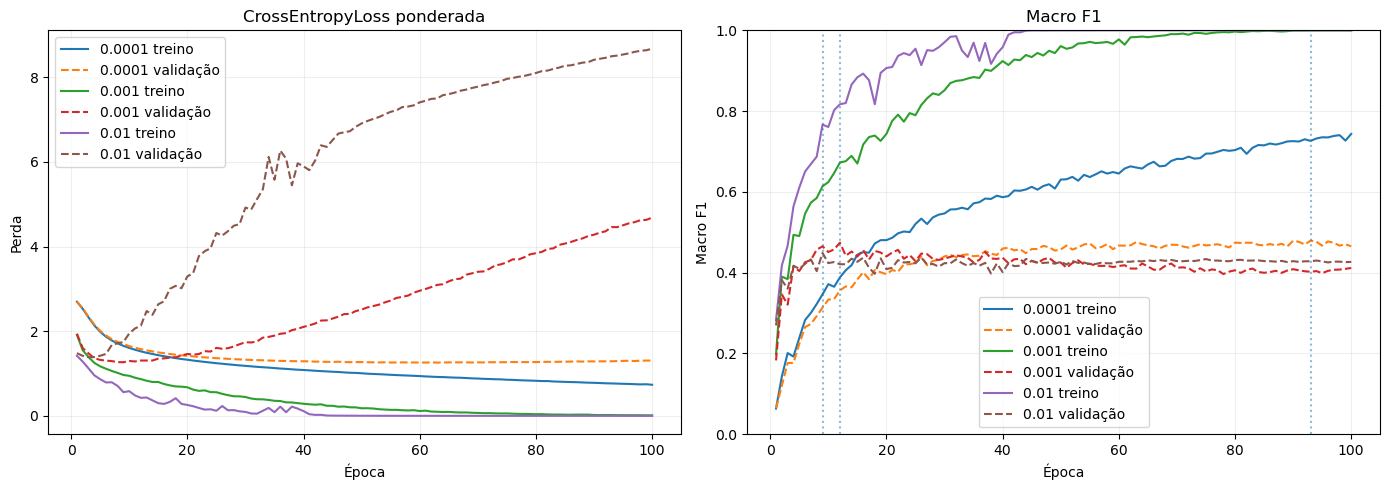

In [3]:
from torch.utils.data import DataLoader, TensorDataset

LEARNING_RATES = [0.0001, 0.001, 0.01]
CONTROL_RATE = 0.001
inner_weights = inverse_frequency_weights(y_inner_train_array)
inner_dataset = TensorDataset(torch.from_numpy(X_inner_train_array), torch.from_numpy(y_inner_train_array))
rate_histories = {}
rate_rows = []

for learning_rate in LEARNING_RATES:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    model = make_mlp(input_size, seed=SEED)
    criterion = torch.nn.CrossEntropyLoss(weight=inner_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=0)
    generator = torch.Generator(device='cpu').manual_seed(SEED)
    loader = DataLoader(inner_dataset,batch_size=BATCH_SIZE,shuffle=True,generator=generator,num_workers=0)
    history={'epoch':[],'train_loss':[],'validation_loss':[],'train_macro_f1':[],'validation_macro_f1':[]}
    start=time.perf_counter()
    for epoch in range(1,MAX_EPOCHS+1):
        model.train()
        for features,targets in loader:
            optimizer.zero_grad(set_to_none=True)
            loss=criterion(model(features),targets)
            loss.backward(); optimizer.step()
        train_loss,train_f1=evaluate_loss_f1(model,X_inner_train_array,y_inner_train_array,criterion)
        val_loss,val_f1=evaluate_loss_f1(model,X_inner_val_array,y_inner_val_array,criterion)
        history['epoch'].append(epoch); history['train_loss'].append(train_loss)
        history['validation_loss'].append(val_loss); history['train_macro_f1'].append(train_f1)
        history['validation_macro_f1'].append(val_f1)
    seconds=time.perf_counter()-start
    best_index=int(np.argmax(history['validation_macro_f1']))
    rate_histories[learning_rate]=history
    rate_rows.append({
        'learning_rate':learning_rate,'best_epoch':history['epoch'][best_index],
        'train_macro_f1':history['train_macro_f1'][best_index],
        'validation_macro_f1':history['validation_macro_f1'][best_index],
        'training_seconds':seconds,
    })

rate_table=pd.DataFrame(rate_rows).sort_values('validation_macro_f1',ascending=False,kind='stable').reset_index(drop=True)
display(rate_table)
control_row=rate_table.loc[rate_table.learning_rate.eq(CONTROL_RATE)].iloc[0]
alternative_table=rate_table.loc[~rate_table.learning_rate.eq(CONTROL_RATE)].sort_values('validation_macro_f1',ascending=False,kind='stable')
selected_rate=float(alternative_table.iloc[0].learning_rate)
selected_epoch=int(alternative_table.iloc[0].best_epoch)
selected_internal_f1=float(alternative_table.iloc[0].validation_macro_f1)
control_wins=float(control_row.validation_macro_f1)>=selected_internal_f1
is_exploratory=control_wins
print(f'Taxa alternativa selecionada para 015: {selected_rate:g}; época={selected_epoch}; Macro F1 interna={selected_internal_f1:.4f}')
print(f'Controlo 0.001: época={int(control_row.best_epoch)}; Macro F1 interna={float(control_row.validation_macro_f1):.4f}')
if control_wins: print('0.001 venceu ou empatou: 012 continua como melhor MLP; 015 é exploratório.')
else: print('A taxa alternativa superou o controlo pela Macro F1 interna.')

fig,axes=plt.subplots(1,2,figsize=(14,5))
for rate in LEARNING_RATES:
    h=rate_histories[rate]
    axes[0].plot(h['epoch'],h['train_loss'],label=f'{rate:g} treino')
    axes[0].plot(h['epoch'],h['validation_loss'],linestyle='--',label=f'{rate:g} validação')
    axes[1].plot(h['epoch'],h['train_macro_f1'],label=f'{rate:g} treino')
    axes[1].plot(h['epoch'],h['validation_macro_f1'],linestyle='--',label=f'{rate:g} validação')
    best=int(rate_table.loc[rate_table.learning_rate.eq(rate),'best_epoch'].iloc[0])
    axes[1].axvline(best,linestyle=':',alpha=.5)
axes[0].set(title='CrossEntropyLoss ponderada',xlabel='Época',ylabel='Perda')
axes[1].set(title='Macro F1',xlabel='Época',ylabel='Macro F1',ylim=(0,1))
for ax in axes: ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.show()

## Reajuste nos 80% e avaliação única na validação fixa

Reajustamos preparação e pesos nos 80% completos, treinamos uma rede nova com a taxa alternativa e época escolhidas internamente, e avaliamos uma única vez na validação fixa. Comparamos Macro F1 e accuracy com o 012 (0,4073 e 0,4168) e os F1/recalls por classe, destacando 18–19, 40–44 e 75–79 anos.

In [4]:
from sklearn.metrics import accuracy_score, classification_report

full_preprocessor=build_preprocessor(X_train,normalize_numeric=True)
X_train_array=to_dense_float32(full_preprocessor.transform(X_train))
X_val_array=to_dense_float32(full_preprocessor.transform(X_val))
y_train_array=y_train.to_numpy(dtype=np.int64); y_val_array=y_val.to_numpy(dtype=np.int64)
final_weights=inverse_frequency_weights(y_train_array)
final_criterion=torch.nn.CrossEntropyLoss(weight=final_weights)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
final_model=make_mlp(X_train_array.shape[1],seed=SEED)
final_optimizer=torch.optim.Adam(final_model.parameters(),lr=selected_rate,weight_decay=0)
final_dataset=TensorDataset(torch.from_numpy(X_train_array),torch.from_numpy(y_train_array))
final_generator=torch.Generator(device='cpu').manual_seed(SEED)
final_loader=DataLoader(final_dataset,batch_size=BATCH_SIZE,shuffle=True,generator=final_generator,num_workers=0)
for _ in range(selected_epoch):
    final_model.train()
    for features,targets in final_loader:
        final_optimizer.zero_grad(set_to_none=True)
        loss=final_criterion(final_model(features),targets)
        loss.backward(); final_optimizer.step()
final_model.eval()
with torch.no_grad(): final_predictions=final_model(torch.from_numpy(X_val_array)).argmax(dim=1).cpu().numpy()
final_macro_f1=f1_score(y_val_array,final_predictions,labels=list(range(NUM_CLASSES)),average='macro',zero_division=0)
final_accuracy=accuracy_score(y_val_array,final_predictions)
final_report=classification_report(y_val_array,final_predictions,labels=list(range(NUM_CLASSES)),target_names=[str(i) for i in range(NUM_CLASSES)],output_dict=True,zero_division=0)
per_class=pd.DataFrame([{'classe':i,'F1':final_report[str(i)]['f1-score'],'recall':final_report[str(i)]['recall'],'support':int(final_report[str(i)]['support'])} for i in range(NUM_CLASSES)])
print(f'015 selecionado: learning_rate={selected_rate:g}, épocas={selected_epoch}, Macro F1 fixa={final_macro_f1:.4f}, accuracy={final_accuracy:.4f}')
display(per_class)
key=per_class[per_class.classe.isin([1,6,13])].copy()
key['escalão']=key.classe.map({1:'18–19 anos',6:'40–44 anos',13:'75–79 anos'})
key['F1_012']=[0.471698,0.131148,0.125604]
key['recall_012']=[0.735294,0.093023,0.078788]
display(key)
print('Referência 012: Macro F1=0.4073; accuracy=0.4168; classe 1 recall=25/34.')

015 selecionado: learning_rate=0.0001, épocas=93, Macro F1 fixa=0.4224, accuracy=0.4191


,classe,F1,recall,support
0,0,0.657534,0.585366,41
1,1,0.473118,0.647059,34
2,2,0.478873,0.425000,80
3,3,0.381503,0.440000,75
4,4,0.281250,0.300000,90
5,5,0.338346,0.348837,129
6,6,0.346269,0.337209,172
7,7,0.339744,0.306358,173
8,8,0.598901,0.602210,181
9,9,0.575269,0.527094,203


,classe,F1,recall,support,escalão,F1_012,recall_012
1,1,0.473118,0.647059,34,18–19 anos,0.471698,0.735294
6,6,0.346269,0.337209,172,40–44 anos,0.131148,0.093023
13,13,0.215686,0.200000,165,75–79 anos,0.125604,0.078788


Referência 012: Macro F1=0.4073; accuracy=0.4168; classe 1 recall=25/34.


## Exportação, comparação dos CSVs e pontuação

Para exportar reajustamos o pré-processador e os pesos nas 10.962 linhas rotuladas, treinamos outra rede com a taxa alternativa e as épocas selecionadas, e copiamos os `RowId` oficiais pela ordem original. Após validar o CSV, comparamos as previsões por RowId com 014 e os CSVs 012, 013 e 007. Se duas previsões forem idênticas, o arquivo é sinalizado como duplicado e não deve ser apresentado como uma nova submissão.

In [5]:
from pathlib import Path

submission_path=repo_root/'submissions'/'submission_015_mlp_learning_rate.csv'
if submission_path.exists(): raise FileExistsError(f'Não vou substituir: {submission_path}')
examples=[repo_root/'example_submission_10.csv',repo_root/'notebooks'/'example_submission_10.csv',Path.home()/'.Trash'/'example_submission_10 21.31.28.csv']
example_path=next((p for p in examples if p.is_file()),None)
if example_path is None: raise FileNotFoundError('Exemplo oficial com RowId não encontrado.')
example=pd.read_csv(example_path)
if not {'RowId','AGE_RANGE'}.issubset(example.columns): raise ValueError(f'Colunas inesperadas: {example.columns.tolist()}')
row_reference=example[['RowId']].copy()
if row_reference.RowId.isna().any() or row_reference.RowId.duplicated().any(): raise ValueError('RowId oficial ausente ou duplicado.')
X_all=prepared['X_train']; X_test=prepared['X_test']; y_all=prepared['y_train']
if len(X_all)!=10962 or len(X_test)!=3655 or len(row_reference)!=3655: raise ValueError('Dimensões inesperadas de dados.')
export_preprocessor=build_preprocessor(X_all,normalize_numeric=True)
X_all_array=to_dense_float32(export_preprocessor.transform(X_all)); X_test_array=to_dense_float32(export_preprocessor.transform(X_test))
y_all_array=y_all.to_numpy(dtype=np.int64)
export_weights=inverse_frequency_weights(y_all_array)
export_criterion=torch.nn.CrossEntropyLoss(weight=export_weights)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
export_model=make_mlp(X_all_array.shape[1],seed=SEED)
export_optimizer=torch.optim.Adam(export_model.parameters(),lr=selected_rate,weight_decay=0)
export_dataset=TensorDataset(torch.from_numpy(X_all_array),torch.from_numpy(y_all_array))
export_generator=torch.Generator(device='cpu').manual_seed(SEED)
export_loader=DataLoader(export_dataset,batch_size=BATCH_SIZE,shuffle=True,generator=export_generator,num_workers=0)
export_start=time.perf_counter()
for _ in range(selected_epoch):
    export_model.train()
    for features,targets in export_loader:
        export_optimizer.zero_grad(set_to_none=True)
        loss=export_criterion(export_model(features),targets)
        loss.backward(); export_optimizer.step()
export_seconds=time.perf_counter()-export_start
export_model.eval()
with torch.no_grad(): export_predictions=export_model(torch.from_numpy(X_test_array)).argmax(dim=1).cpu().numpy().astype(np.int64)
submission=row_reference.copy(); submission['AGE_RANGE']=export_predictions
if submission.columns.tolist()!=['RowId','AGE_RANGE'] or not pd.api.types.is_integer_dtype(submission.AGE_RANGE) or not submission.AGE_RANGE.between(0,15).all(): raise ValueError('Formato ou classes inválidas antes de guardar.')
submission_path.parent.mkdir(parents=True,exist_ok=True); submission.to_csv(submission_path,index=False)
check=pd.read_csv(submission_path)
if check.shape!=(3655,2) or check.columns.tolist()!=['RowId','AGE_RANGE'] or not check.RowId.equals(row_reference.RowId): raise ValueError('CSV lido não respeita dimensão, cabeçalho ou ordem RowId.')
if not check.RowId.is_unique or not pd.api.types.is_integer_dtype(check.AGE_RANGE) or not check.AGE_RANGE.between(0,15).all(): raise ValueError('RowId/classes inválidos no CSV gravado.')
print(f'Guardado {submission_path}; learning_rate={selected_rate:g}; época={selected_epoch}; treino={export_seconds:.2f}s')

comparison_paths={'014':repo_root/'submissions'/'submission_014_xgboost_mlp.csv','012':repo_root/'submissions'/'submission_012_mlp_perda_ponderada.csv','013':repo_root/'submissions'/'submission_013_mlp_arquitetura.csv','007':repo_root/'submissions'/'submission_007_xgboost.csv'}
differences=[]
for name,p in comparison_paths.items():
    if p.is_file():
        other=pd.read_csv(p)
        if other.columns.tolist()!=['RowId','AGE_RANGE'] or not other.RowId.equals(check.RowId): raise ValueError(f'CSV {name} desalinhado por RowId.')
        count=int((check.AGE_RANGE.to_numpy()!=other.AGE_RANGE.to_numpy()).sum())
        differences.append({'comparado_com':name,'previsoes_diferentes':count,'total':len(check),'duplicado':count==0})
difference_table=pd.DataFrame(differences); display(difference_table)
if any(row['comparado_com']=='014' and row['duplicado'] for row in differences):
    print('DUPLICADO: submissões 014 e 015 têm as mesmas previsões; não apresentar 015 como submissão nova.')
else:
    print('As previsões 014 e 015 são distintas; ambas representam novas submissões.')

Guardado /Users/eduardaferreira/daa-kaggle-2026-2027/submissions/submission_015_mlp_learning_rate.csv; learning_rate=0.0001; época=93; treino=25.84s


,comparado_com,previsoes_diferentes,total,duplicado
0,014,1184,3655,False
1,012,935,3655,False
2,007,1512,3655,False


As previsões 014 e 015 são distintas; ambas representam novas submissões.


## Conclusão e Decisão
- Data: 10/11
- Pontuação Kaggle: 0.44
- Conclusão: A taxa de aprendizagem de 0,0001, com 93 épocas, deu o melhor MLP até agora. Face ao 012, a Macro F1 subiu de 0,4073 para 0,4224 na validação fixa e de 0,43 para 0,44 no Kaggle. Nos 18–19 anos, o F1 ficou praticamente igual, mas o recall desceu de 25/34 para 22/34.
- Melhorias: Comparar Adam e SGD com a mesma arquitetura e perda ponderada, escolhendo a taxa de aprendizagem e o número de épocas de cada otimizador na validação interna.

- A taxa alternativa **0,0001** venceu na validação interna (Macro F1 **0,4792**, época **93**) sobre o controlo 0,001 (0,4742, época 12). Na validação fixa, obteve Macro F1 **0,4224** e accuracy **0,4191**, acima do 012 (**0,4073** e **0,4168**); o 015 não é exploratório nesta comparação. Para 18–19 anos, F1 **0,4731** e recall **0,6471 (22/34)**; para 40–44, F1 **0,3463**, recall **0,3372**; para 75–79, F1 **0,2157**, recall **0,2000**.



